In [1]:
# Paso 2: Preprocesamiento de los datos

In [2]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import sys
import os
from sklearn.preprocessing import StandardScaler


ruta_raiz = os.path.abspath('../..')
if ruta_raiz not in sys.path:
    sys.path.append(ruta_raiz)

from config.rutas import RUTA_DATOS_CRUDOS



# Casteo de datos a sus datos correspondientes

In [3]:
COLUMNAS_NUMERICAS = [
    'Global_active_power', 'Global_reactive_power', 'Voltage',
    'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3'
]

def casteo_datos(RUTA_DATOS_CRUDOS):
    # Carga con na_values='?' y low_memory=False para evitar advertencias de tipos mixtos
    df_casteado = pd.read_csv(RUTA_DATOS_CRUDOS, sep=';', na_values='?', low_memory=False)
    
    # Combinar Date y Time en una sola columna con formato explícito para acelerar la carga
    df_casteado['Date-time'] = pd.to_datetime(
        df_casteado['Date'] + ' ' + df_casteado['Time'], 
        format='%d/%m/%Y %H:%M:%S'
    )
    
    # Establecer la columna Date-time como índice ordenado y eliminar las columnas Date y Time
    df_casteado = df_casteado.set_index('Date-time').drop(columns=['Date', 'Time']).sort_index()

    # Casteo de las columnas a tipo float64
    for col in COLUMNAS_NUMERICAS:
        df_casteado[col] = pd.to_numeric(df_casteado[col], errors='coerce')

    return df_casteado


In [4]:
df_casteado= casteo_datos(RUTA_DATOS_CRUDOS)

/tmp/ipykernel_25665/4058502823.py:2: DtypeWarning: Columns (2,3,4,5,6,7) have mixed types. Specify dtype option on import or set low_memory=False.
  df_casteado= pd.read_csv(RUTA_DATOS_CRUDOS,sep=';')
/tmp/ipykernel_25665/4058502823.py:4: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_casteado['Date-time'] = pd.to_datetime(df_casteado['Date'].astype(str) + ' ' + df_casteado['Time'].astype(str))


In [5]:
df_casteado.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2075259 entries, 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Data columns (total 7 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float64
 1   Global_reactive_power  float64
 2   Voltage                float64
 3   Global_intensity       float64
 4   Sub_metering_1         float64
 5   Sub_metering_2         float64
 6   Sub_metering_3         float64
dtypes: float64(7)
memory usage: 126.7 MB


# Normalización de Variables Cualitativas

unificación de mayúsculas/minúsculas, eliminación de espacios en blanco redundantes y estandarización de acentos.

Tras el casteo inicial, donde las columnas `Date` y `Time` se fusionaron para estructurar el índice temporal `DatetimeIndex`, todas las columnas restantes en el dataset son cuantitativas continuas (de tipo `float64`). Al no existir variables cualitativas ni categóricas de tipo cadena de texto (`object` o `string`), la normalización cualitativa **no aplica** en este conjunto de datos.


# Deduplicación de Registros

En series de tiempo con frecuencia de muestreo fija (1 minuto), el criterio rector de unicidad es la **marca temporal (timestamp)**. Dos registros en minutos distintos pueden registrar valores idénticos de consumo, por lo que eliminar filas completas duplicadas sin considerar el tiempo destruiría información válida.

se evalúa si existen timestamps repetidos en el índice temporal:


In [ ]:
duplicados_tiempo = df_casteado.index.duplicated().sum()
duplicados_filas = df_casteado.duplicated().sum()
print(f'Timestamps duplicados en el índice temporal: {duplicados_tiempo}')
print(f'Filas exactamente duplicadas en todas las columnas: {duplicados_filas}')


Timestamps duplicados en el índice temporal: 0
Filas exactamente duplicadas en todas las columnas: 0


 existen **0 timestamps duplicados** y **0 filas duplicadas** en el conjunto de datos, por lo que la serie temporal mantiene una secuencia temporal estricta y no se requiere descartar observaciones por redundancia de registro.


# Imputación de Valores Nulos y Normalización

Como se puede observar, casteadas de manera correcta nuestras variables numéricas asi como tambien se establecio de manera correcta el indice de nuestra serie, usando la nueva columna creada llamada 'Date-Time', por ello pasamos a la imputación de valores nulos.


In [6]:
df_casteado.isnull().sum()

Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Text(0.5, 0, 'Características')

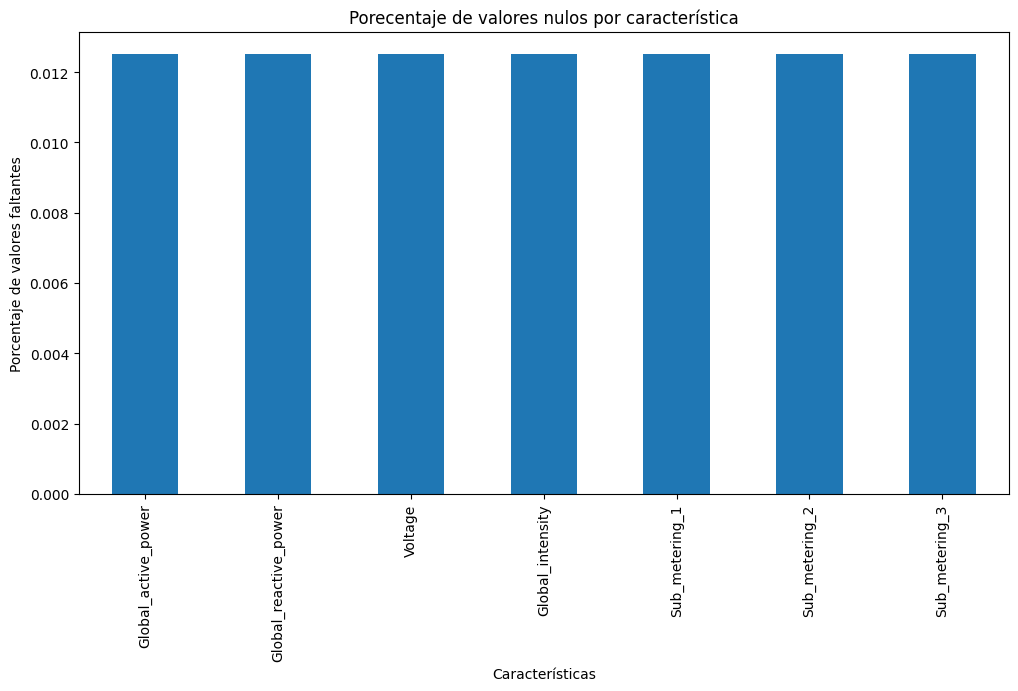

In [7]:
plt.figure(figsize=(20,10))
plt.title('Porecentaje de valores nulos por característica')
df_casteado.isnull().mean().plot.bar(figsize=(12,6))
plt.ylabel('Porcentaje de valores faltantes')
plt.xlabel('Características')

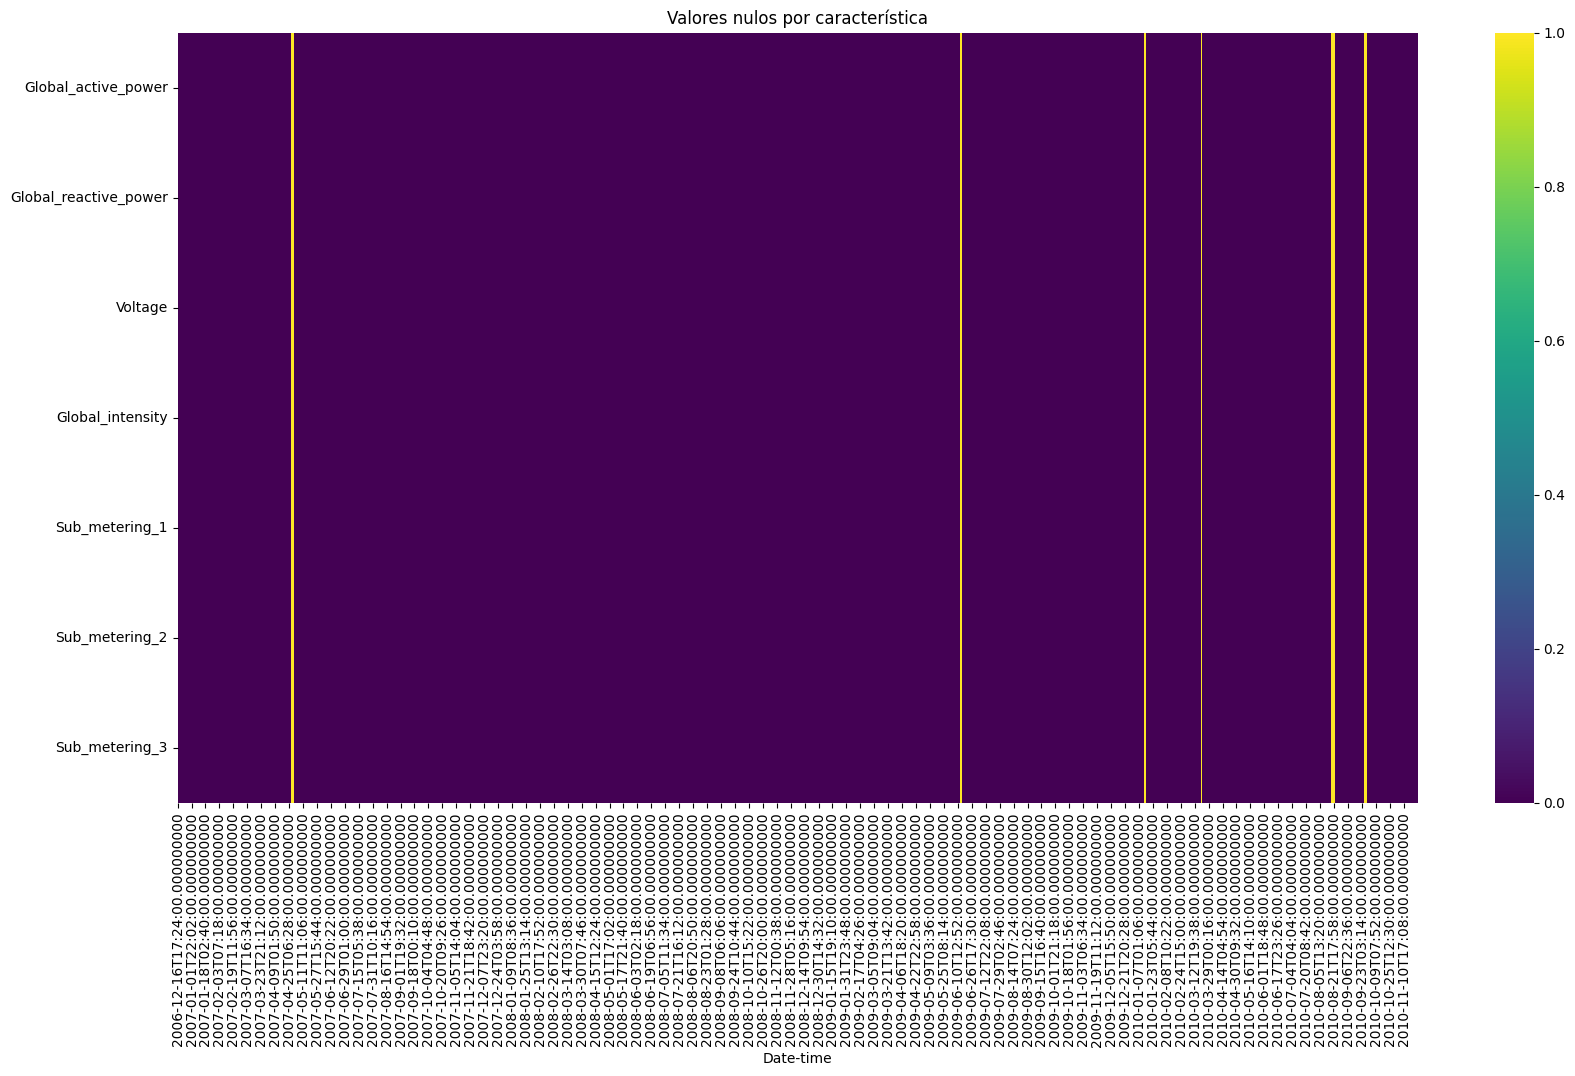

In [8]:
plt.figure(figsize=(20,10))
plt.title('Valores nulos por característica')
sns.heatmap(df_casteado.isnull().T, cmap='viridis')
plt.show()

Como se observan en los graficos anteriores, nuestras variables cuantitativas tienen un porcentaje de valores nulos de aproximadamente 1.25% (0.0125 en proporción) y como se puede notar, dichas columnas tienen los valores nulos exactamente en los mismos indices. 
Para la imputación de los datos, se opta por realizar una interpolación puesto a que como se mencionó anteriormente la tasa de nulos es relativamente pequeña y la complejidad no será demasiada al momento de ejecutarse. 


Se usará la normalización con *Z-score* pues el ideal para el uso de PCA que es el siguiente paso a realizar en la práctica. 



In [9]:
def limpieza_imputacion(df_casteado):
    
    df_interpolado = df_casteado.interpolate()
    scaler = StandardScaler()
    df_z_score = pd.DataFrame(scaler.fit_transform(df_interpolado), columns=df_interpolado.columns,index=df_interpolado.index)
    
    return df_z_score

In [10]:
df_limpio=limpieza_imputacion(df_casteado)
df_limpio.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Date-time,,,,,,,
2006-12-16 17:24:00,2.969445,2.618328,-1.850903,3.114240,-0.181412,-0.049982,1.254491
2006-12-16 17:25:00,4.056249,2.778443,-2.224618,4.153939,-0.181412,-0.049982,1.135667
2006-12-16 17:26:00,4.069549,3.329949,-2.329629,4.153939,-0.181412,0.122830,1.254491
2006-12-16 17:27:00,4.082849,3.365531,-2.190644,4.153939,-0.181412,-0.049982,1.254491
2006-12-16 17:28:00,2.446943,3.596807,-1.591465,2.526585,-0.181412,-0.049982,1.254491


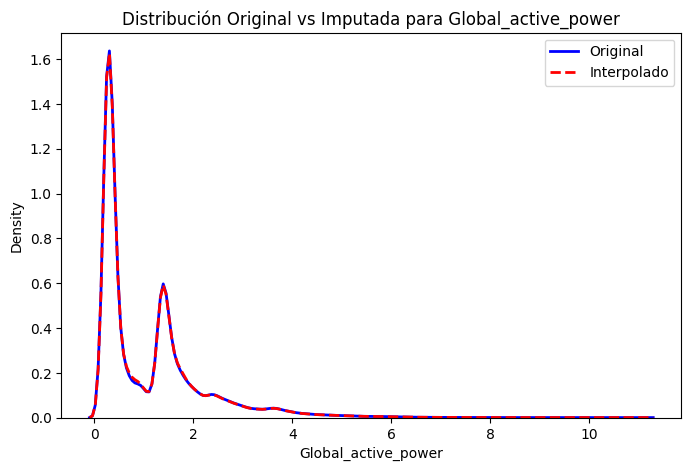

In [12]:
df_interpolado = df_casteado.interpolate()
plt.figure(figsize=(8, 5))
sns.kdeplot(df_casteado['Global_active_power'], label='Original', color='blue', linewidth=2)
sns.kdeplot(df_interpolado['Global_active_power'], label='Interpolado', color='red', linestyle='--', linewidth=2)
plt.title(f'Distribución Original vs Imputada para {"Global_active_power"}')
plt.legend()
plt.show()

Como se observa en el gráfico anterior, tomando como referencia la columna *'Global_active_power*, la curva de densidad del dataset una vez interpolado se ajusta de manera adecuada a la curva del dataset original, por lo que se realizo de manera eficiente nuestra imputación. 